In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns

from sklearn.metrics import mean_squared_log_error
from sklearn.preprocessing import LabelEncoder

from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

ModuleNotFoundError: No module named 'lightgbm'

In [ ]:
df_train = pd.read_csv("/kaggle/input/competitions/store-sales-time-series-forecasting/train.csv", parse_dates=["date"])
df_test = pd.read_csv("/kaggle/input/competitions/store-sales-time-series-forecasting/test.csv", parse_dates=["date"])
df_oil = pd.read_csv("/kaggle/input/competitions/store-sales-time-series-forecasting/oil.csv", parse_dates=["date"])
df_stores = pd.read_csv("/kaggle/input/competitions/store-sales-time-series-forecasting/stores.csv")
df_transactions = pd.read_csv("/kaggle/input/competitions/store-sales-time-series-forecasting/transactions.csv", parse_dates=["date"])
df_holidays = pd.read_csv("/kaggle/input/competitions/store-sales-time-series-forecasting/holidays_events.csv", parse_dates=["date"])

In [ ]:
datasets = {
    "Train": df_train,
    "Test": df_test,
    "Oil": df_oil,
    "Stores": df_stores,
    "Transactions": df_transactions,
    "Holidays": df_holidays
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Train: (3000888, 6)
Test: (28512, 5)
Oil: (1218, 2)
Stores: (54, 5)
Transactions: (83488, 3)
Holidays: (350, 6)


In [ ]:
def inspect_numerical_data(df):
    
    print("=== Data Info ===")
    df_train.info()

    print("\n=== Numerical Features Description ===")
    display(df_train.describe())
inspect_numerical_data(df_train)

=== Data Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           int64         
 1   date         datetime64[ns]
 2   store_nbr    int64         
 3   family       object        
 4   sales        float64       
 5   onpromotion  int64         
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 137.4+ MB

=== Numerical Features Description ===


,id,date,store_nbr,sales,onpromotion
count,3.000888e+06,3000888,3.000888e+06,3.000888e+06,3.000888e+06
mean,1.500444e+06,2015-04-24 08:27:04.703088384,2.750000e+01,3.577757e+02,2.602770e+00
min,0.000000e+00,2013-01-01 00:00:00,1.000000e+00,0.000000e+00,0.000000e+00
25%,7.502218e+05,2014-02-26 18:00:00,1.400000e+01,0.000000e+00,0.000000e+00
50%,1.500444e+06,2015-04-24 12:00:00,2.750000e+01,1.100000e+01,0.000000e+00
75%,2.250665e+06,2016-06-19 06:00:00,4.100000e+01,1.958473e+02,0.000000e+00
max,3.000887e+06,2017-08-15 00:00:00,5.400000e+01,1.247170e+05,7.410000e+02
std,8.662819e+05,NaN,1.558579e+01,1.101998e+03,1.221888e+01


In [ ]:
def inspect_categorical_data(df):
    categorical_df = df.select_dtypes(include=["object", "category", "bool"])

    for col in categorical_df.columns:
        print(f"\n=== {col} ===")
        print(f"Number of unique classes: {categorical_df[col].nunique(dropna=False)}")
        print(categorical_df[col].value_counts(dropna=False))
inspect_categorical_data(df_train)


=== family ===
Number of unique classes: 33
family
AUTOMOTIVE                    90936
BABY CARE                     90936
BEAUTY                        90936
BEVERAGES                     90936
BOOKS                         90936
BREAD/BAKERY                  90936
CELEBRATION                   90936
CLEANING                      90936
DAIRY                         90936
DELI                          90936
EGGS                          90936
FROZEN FOODS                  90936
GROCERY I                     90936
GROCERY II                    90936
HARDWARE                      90936
HOME AND KITCHEN I            90936
HOME AND KITCHEN II           90936
HOME APPLIANCES               90936
HOME CARE                     90936
LADIESWEAR                    90936
LAWN AND GARDEN               90936
LINGERIE                      90936
LIQUOR,WINE,BEER              90936
MAGAZINES                     90936
MEATS                         90936
PERSONAL CARE                 90936
PET SUPPLIES

In [ ]:
def inspect_missing_values(df):
    missing = df.isnull().sum()

    missing_df = pd.DataFrame({
        "Missing Values": missing,
        "Missing Percentage (%)": (missing / len(df)) * 100
    })

    missing_df = missing_df[missing_df["Missing Values"] > 0]
    missing_df = missing_df.sort_values(
        by="Missing Percentage (%)",
        ascending=False
    )

    return missing_df
inspect_missing_values(df_train)

,Missing Values,Missing Percentage (%)


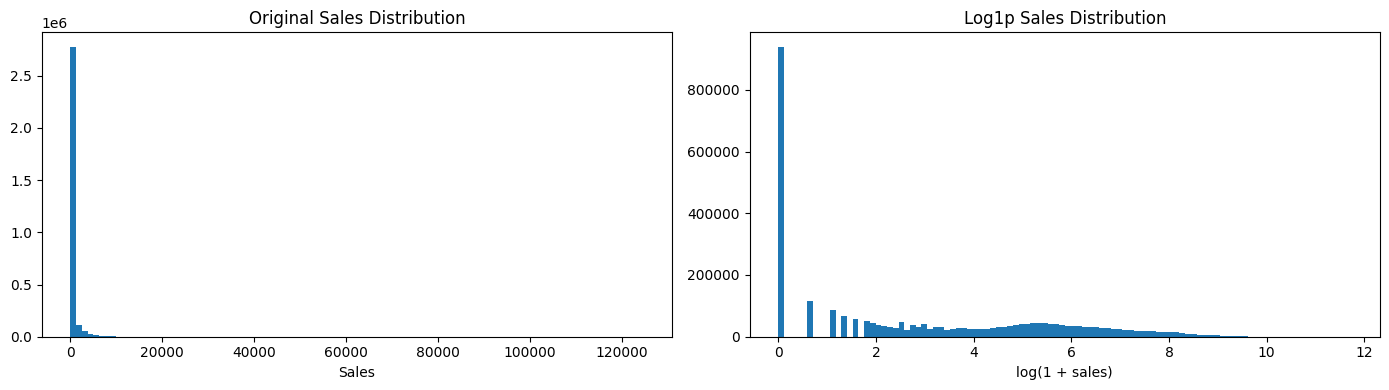

In [ ]:
import matplotlib.pyplot as plt

sales = df_train["sales"].dropna()

# Keep the original sales values unchanged
log_sales = np.log1p(sales)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

ax[0].hist(sales, bins=100)
ax[0].set_title("Original Sales Distribution")
ax[0].set_xlabel("Sales")

ax[1].hist(log_sales, bins=100)
ax[1].set_title("Log1p Sales Distribution")
ax[1].set_xlabel("log(1 + sales)")

plt.tight_layout()
plt.show()

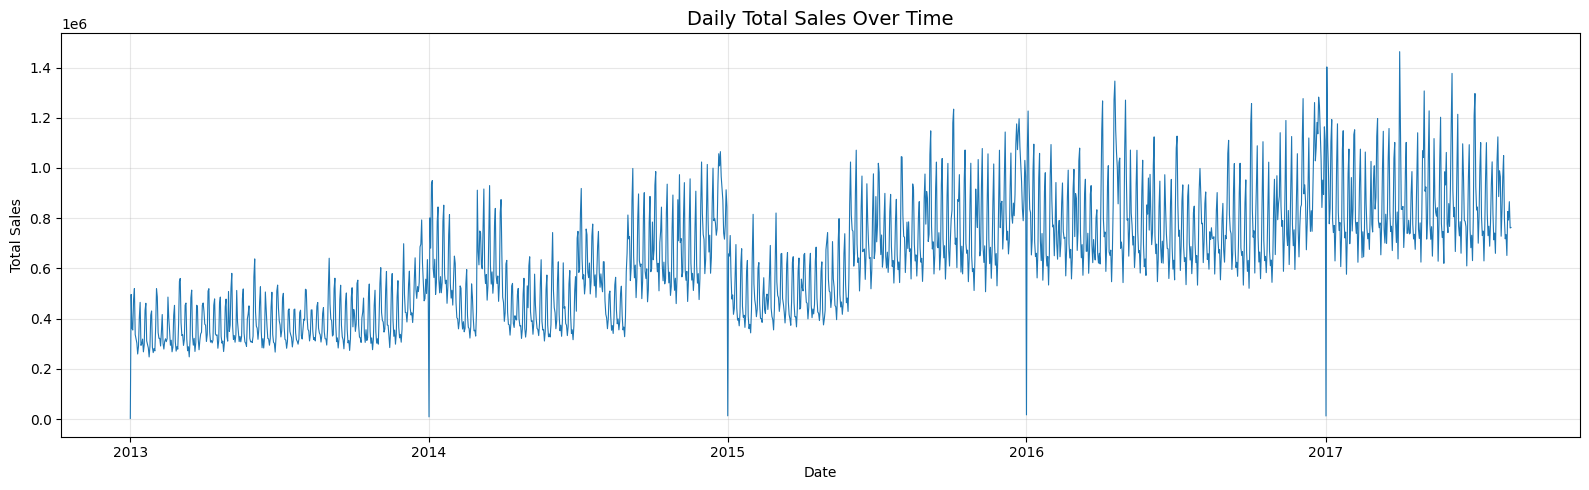

In [ ]:
# 1. Aggregate sales by date
daily_sales = (
    df_train.groupby("date", as_index=False)["sales"]
    .sum()
    .sort_values("date")
)

# 2. Plot daily sales
plt.figure(figsize=(16, 5))

plt.plot(
    daily_sales["date"],
    daily_sales["sales"],
    linewidth=0.8
)

plt.title("Daily Total Sales Over Time", fontsize=14)
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

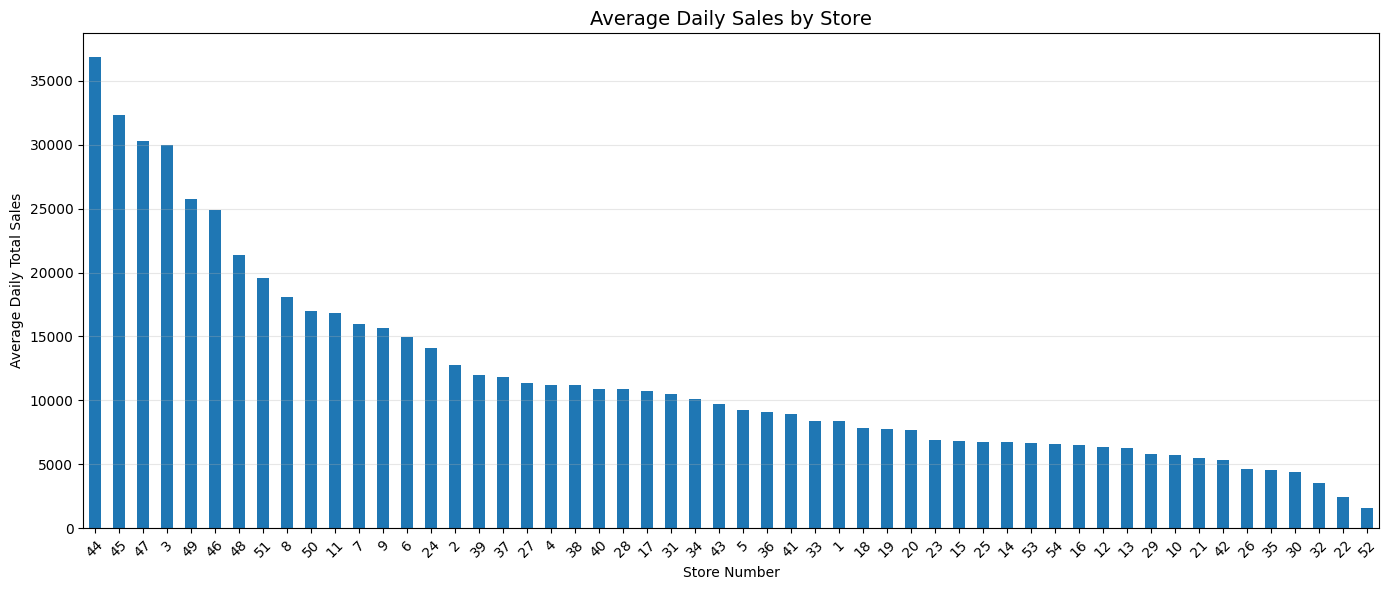

In [ ]:
# 1. Calculate total sales per store per day
daily_store_sales = (
    df_train.groupby(["date", "store_nbr"])["sales"]
    .sum()
    .reset_index()
)

# 2. Calculate average daily sales per store
store_sales = (
    daily_store_sales.groupby("store_nbr")["sales"]
    .mean()
    .sort_values(ascending=False)
)

# 3. Plot the comparison
plt.figure(figsize=(14, 6))

store_sales.plot(kind="bar")

plt.title("Average Daily Sales by Store", fontsize=14)
plt.xlabel("Store Number")
plt.ylabel("Average Daily Total Sales")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

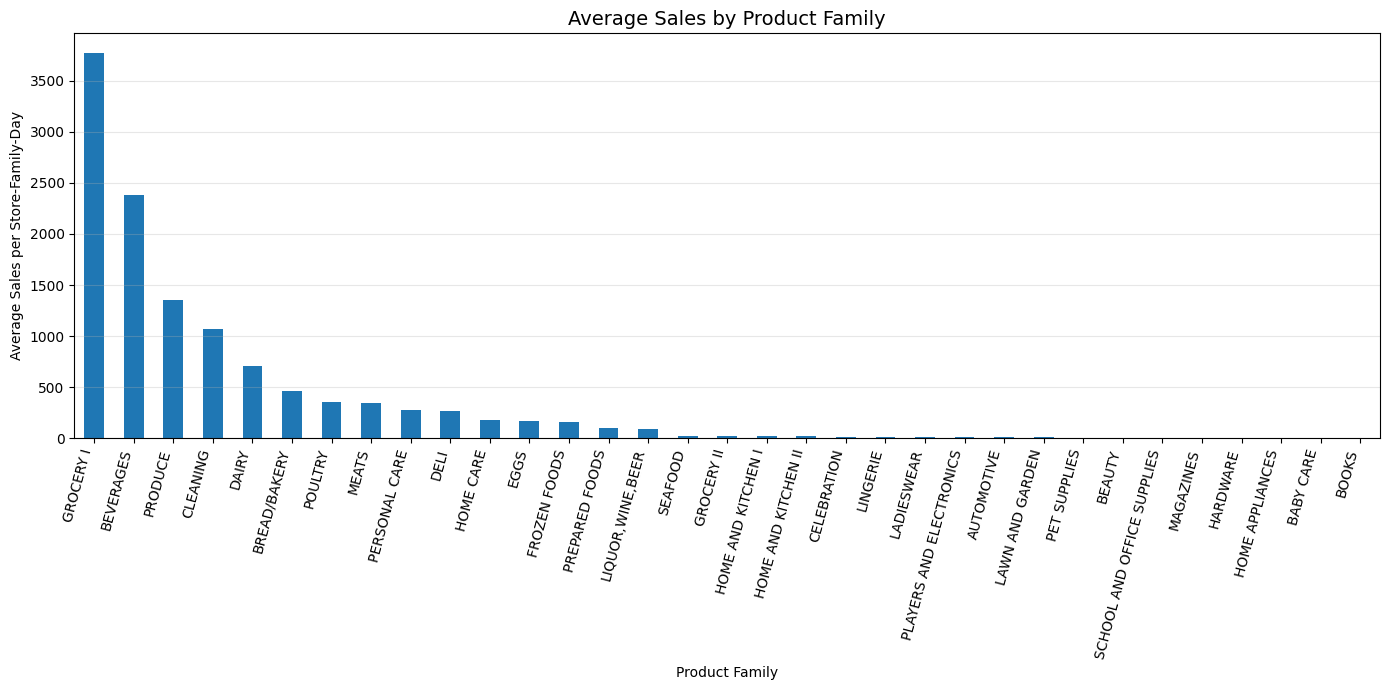

In [ ]:

import matplotlib.pyplot as plt

# 1. Calculate average sales by product family
family_sales = (
    df_train.groupby("family")["sales"]
    .mean()
    .sort_values(ascending=False)
)

# 2. Plot the comparison
plt.figure(figsize=(14, 7))

family_sales.plot(kind="bar")

plt.title("Average Sales by Product Family", fontsize=14)
plt.xlabel("Product Family")
plt.ylabel("Average Sales per Store-Family-Day")
plt.xticks(rotation=75, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# 1. Prepare the training dataset
train_part = df_train.copy()
train_part["is_test"] = 0

# 2. Prepare the test dataset
test_part = df_test.copy()
test_part["sales"] = np.nan
test_part["is_test"] = 1

# 3. Combine train and test vertically
data = pd.concat(
    [train_part, test_part],
    ignore_index=True,
    sort=False
)

# 4. Sort chronologically for each store and family
data = data.sort_values(
    ["store_nbr", "family", "date"]
).reset_index(drop=True)

# 5. Check the result
print("Combined shape:", data.shape)
print("\nDataset split:")
print(data["is_test"].value_counts())

print("\nMissing sales:")
print(data["sales"].isna().sum())

display(data.head())

Combined shape: (3029400, 7)

Dataset split:
is_test
0    3000888
1      28512
Name: count, dtype: int64

Missing sales:
28512


,id,date,store_nbr,family,sales,onpromotion,is_test
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,0
1,1782,2013-01-02,1,AUTOMOTIVE,2.0,0,0
2,3564,2013-01-03,1,AUTOMOTIVE,3.0,0,0
3,5346,2013-01-04,1,AUTOMOTIVE,3.0,0,0
4,7128,2013-01-05,1,AUTOMOTIVE,5.0,0,0


In [ ]:
# Sort oil data chronologically
df_oil = df_oil.sort_values("date").copy()

# Fill missing oil prices
df_oil["dcoilwtico"] = (
    df_oil["dcoilwtico"]
    .ffill()
    .bfill()
)

# Check remaining missing values
print("Missing oil prices:", df_oil["dcoilwtico"].isna().sum())


Missing oil prices: 0


In [ ]:
# 1. Copy the holidays dataset
holiday_base = df_holidays.copy()

# 2. Create holiday indicator and type features
holiday_base["is_holiday"] = (
    (holiday_base["transferred"] == False)
    & (holiday_base["type"] != "Work Day")
).astype(int)

holiday_base["holiday_type"] = holiday_base["type"].astype(str)

# 3. Prepare national holidays: one row per date
national_holidays = (
    holiday_base[holiday_base["locale"] == "National"]
    .groupby("date", as_index=False)
    .agg(
        national_holiday=("is_holiday", "max"),
        national_holiday_type=("holiday_type", "first")
    )
)

# 4. Prepare regional holidays: one row per date and state
regional_holidays = (
    holiday_base[holiday_base["locale"] == "Regional"]
    .groupby(["date", "locale_name"], as_index=False)
    .agg(
        regional_holiday=("is_holiday", "max"),
        regional_holiday_type=("holiday_type", "first")
    )
    .rename(columns={"locale_name": "state"})
)

# 5. Prepare local holidays: one row per date and city
local_holidays = (
    holiday_base[holiday_base["locale"] == "Local"]
    .groupby(["date", "locale_name"], as_index=False)
    .agg(
        local_holiday=("is_holiday", "max"),
        local_holiday_type=("holiday_type", "first")
    )
    .rename(columns={"locale_name": "city"})
)

# 6. Check that merge keys are unique
print("National duplicate dates:",
      national_holidays.duplicated(["date"]).sum())

print("Regional duplicate keys:",
      regional_holidays.duplicated(["date", "state"]).sum())

print("Local duplicate keys:",
      local_holidays.duplicated(["date", "city"]).sum())

# 7. Check the prepared tables
display(national_holidays.head())
display(regional_holidays.head())
display(local_holidays.head())


National duplicate dates: 0
Regional duplicate keys: 0
Local duplicate keys: 0


,date,national_holiday,national_holiday_type
0,2012-08-10,1,Holiday
1,2012-10-09,0,Holiday
2,2012-10-12,1,Transfer
3,2012-11-02,1,Holiday
4,2012-11-03,1,Holiday


,date,state,regional_holiday,regional_holiday_type
0,2012-04-01,Cotopaxi,1,Holiday
1,2012-06-25,Imbabura,1,Holiday
2,2012-11-06,Santo Domingo de los Tsachilas,1,Holiday
3,2012-11-07,Santa Elena,1,Holiday
4,2013-04-01,Cotopaxi,1,Holiday


,date,city,local_holiday,local_holiday_type
0,2012-03-02,Manta,1,Holiday
1,2012-04-12,Cuenca,1,Holiday
2,2012-04-14,Libertad,1,Holiday
3,2012-04-21,Riobamba,1,Holiday
4,2012-05-12,Puyo,1,Holiday


In [ ]:
# Sort transactions by store and date
df_transactions = df_transactions.sort_values(
    ["store_nbr", "date"]
).copy()

# Check the result
display(df_transactions.head())

print("Shape:", df_transactions.shape)
print("Missing values:\n", df_transactions.isna().sum())

,date,store_nbr,transactions
1,2013-01-02,1,2111
47,2013-01-03,1,1833
93,2013-01-04,1,1863
139,2013-01-05,1,1509
185,2013-01-06,1,520


Shape: (83488, 3)
Missing values:
 date            0
store_nbr       0
transactions    0
dtype: int64


In [ ]:
# Merge store information into the main dataset
data = data.merge(
    df_stores,
    on="store_nbr",
    how="left",
    validate="many_to_one"
)

# Check the result
print("Dataset shape:", data.shape)
print("Missing values in store features:")
print(data[["city", "state", "type", "cluster"]].isna().sum())

Dataset shape: (3029400, 11)
Missing values in store features:
city       0
state      0
type       0
cluster    0
dtype: int64


In [ ]:
# 1. Sort the oil dataset by date
df_oil = df_oil.sort_values("date").copy()

# 2. Merge oil prices into the main dataset
data = data.merge(
    df_oil,
    on="date",
    how="left",
    validate="many_to_one"
)

print(data.head())

# 3. Sort the main dataset by date
data = data.sort_values("date").copy()

# 4. Fill missing oil prices using the previous known price
data["dcoilwtico"] = data["dcoilwtico"].ffill()

# 5. Check the result
print("Dataset shape:", data.shape)
print("\nMissing values in oil features:")
print(data[["dcoilwtico"]].isna().sum())

display(data.head())

     id       date  store_nbr      family  sales  onpromotion  is_test   city  \
0     0 2013-01-01          1  AUTOMOTIVE    0.0            0        0  Quito   
1  1782 2013-01-02          1  AUTOMOTIVE    2.0            0        0  Quito   
2  3564 2013-01-03          1  AUTOMOTIVE    3.0            0        0  Quito   
3  5346 2013-01-04          1  AUTOMOTIVE    3.0            0        0  Quito   
4  7128 2013-01-05          1  AUTOMOTIVE    5.0            0        0  Quito   

       state type  cluster  dcoilwtico  
0  Pichincha    D       13       93.14  
1  Pichincha    D       13       93.14  
2  Pichincha    D       13       92.97  
3  Pichincha    D       13       93.12  
4  Pichincha    D       13         NaN  
Dataset shape: (3029400, 12)

Missing values in oil features:
dcoilwtico    0
dtype: int64


,id,date,store_nbr,family,sales,onpromotion,is_test,city,state,type,cluster,dcoilwtico
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,0,Quito,Pichincha,D,13,93.14
2504100,1308,2013-01-01,45,LINGERIE,0.0,0,0,Quito,Pichincha,A,11,93.14
477700,1766,2013-01-01,9,HOME APPLIANCES,0.0,0,0,Quito,Pichincha,B,6,93.14
2502400,1307,2013-01-01,45,LAWN AND GARDEN,0.0,0,0,Quito,Pichincha,A,11,93.14
479400,1767,2013-01-01,9,HOME CARE,0.0,0,0,Quito,Pichincha,B,6,93.14


In [ ]:

# 1. Copy and prepare the holidays dataset
holiday_base = df_holidays.copy()

holiday_base["is_holiday"] = (
    (holiday_base["transferred"] == False)
    & (holiday_base["type"] != "Work Day")
).astype(int)

holiday_base["holiday_type"] = holiday_base["type"].astype(str)


# 2. Prepare national holiday features
national_holidays = (
    holiday_base[holiday_base["locale"] == "National"]
    .groupby("date", as_index=False)
    .agg(
        national_holiday=("is_holiday", "max"),
        national_holiday_type=("holiday_type", "first")
    )
)


# 3. Prepare regional holiday features
regional_holidays = (
    holiday_base[holiday_base["locale"] == "Regional"]
    .groupby(["date", "locale_name"], as_index=False)
    .agg(
        regional_holiday=("is_holiday", "max"),
        regional_holiday_type=("holiday_type", "first")
    )
    .rename(columns={"locale_name": "state"})
)


# 4. Prepare local holiday features
local_holidays = (
    holiday_base[holiday_base["locale"] == "Local"]
    .groupby(["date", "locale_name"], as_index=False)
    .agg(
        local_holiday=("is_holiday", "max"),
        local_holiday_type=("holiday_type", "first")
    )
    .rename(columns={"locale_name": "city"})
)


# 5. Merge national holidays by date
data = data.merge(
    national_holidays,
    on="date",
    how="left",
    validate="many_to_one"
)


# 6. Merge regional holidays by date and state
data = data.merge(
    regional_holidays,
    on=["date", "state"],
    how="left",
    validate="many_to_one"
)


# 7. Merge local holidays by date and city
data = data.merge(
    local_holidays,
    on=["date", "city"],
    how="left",
    validate="many_to_one"
)


# 8. Fill missing holiday indicators with 0
holiday_flags = [
    "national_holiday",
    "regional_holiday",
    "local_holiday"
]

data[holiday_flags] = (
    data[holiday_flags]
    .fillna(0)
    .astype(int)
)


# 9. Fill missing holiday types with "None"
holiday_type_cols = [
    "national_holiday_type",
    "regional_holiday_type",
    "local_holiday_type"
]

data[holiday_type_cols] = data[holiday_type_cols].fillna("None")


# 10. Check the result
print("Dataset shape:", data.shape)

print("\nMissing values in holiday features:")
print(data[holiday_flags + holiday_type_cols].isna().sum())

display(data.head())


Dataset shape: (3029400, 18)

Missing values in holiday features:
national_holiday         0
regional_holiday         0
local_holiday            0
national_holiday_type    0
regional_holiday_type    0
local_holiday_type       0
dtype: int64


,id,date,store_nbr,family,sales,onpromotion,is_test,city,state,type,cluster,dcoilwtico,national_holiday,national_holiday_type,regional_holiday,regional_holiday_type,local_holiday,local_holiday_type
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,0,Quito,Pichincha,D,13,93.14,1,Holiday,0,None,0,None
1,1308,2013-01-01,45,LINGERIE,0.0,0,0,Quito,Pichincha,A,11,93.14,1,Holiday,0,None,0,None
2,1766,2013-01-01,9,HOME APPLIANCES,0.0,0,0,Quito,Pichincha,B,6,93.14,1,Holiday,0,None,0,None
3,1307,2013-01-01,45,LAWN AND GARDEN,0.0,0,0,Quito,Pichincha,A,11,93.14,1,Holiday,0,None,0,None
4,1767,2013-01-01,9,HOME CARE,0.0,0,0,Quito,Pichincha,B,6,93.14,1,Holiday,0,None,0,None


In [ ]:
# ============================================================
# 1. CALENDAR FEATURES
# ============================================================

data["year"] = data["date"].dt.year
data["month"] = data["date"].dt.month
data["day"] = data["date"].dt.day
data["dayofweek"] = data["date"].dt.dayofweek
data["dayofyear"] = data["date"].dt.dayofyear
data["weekofyear"] = data["date"].dt.isocalendar().week.astype(int)
data["quarter"] = data["date"].dt.quarter

data["is_weekend"] = data["dayofweek"].isin([5, 6]).astype(int)

data["is_month_start"] = data["date"].dt.is_month_start.astype(int)
data["is_month_end"] = data["date"].dt.is_month_end.astype(int)
data["is_quarter_start"] = data["date"].dt.is_quarter_start.astype(int)
data["is_quarter_end"] = data["date"].dt.is_quarter_end.astype(int)

data["time_idx"] = (
    data["date"] - data["date"].min()
).dt.days


# ============================================================
# 2. SEASONAL FEATURES
# ============================================================

data["dow_sin"] = np.sin(
    2 * np.pi * data["dayofweek"] / 7
)
data["dow_cos"] = np.cos(
    2 * np.pi * data["dayofweek"] / 7
)

data["month_sin"] = np.sin(
    2 * np.pi * data["month"] / 12
)
data["month_cos"] = np.cos(
    2 * np.pi * data["month"] / 12
)

data["doy_sin"] = np.sin(
    2 * np.pi * data["dayofyear"] / 365.25
)
data["doy_cos"] = np.cos(
    2 * np.pi * data["dayofyear"] / 365.25
)


# ============================================================
# 3. PAYDAY FEATURES
# ============================================================

data["payday"] = (
    (data["day"] == 15) |
    data["is_month_end"].astype(bool)
).astype(int)

data["days_to_15"] = (15 - data["day"]).abs()


# ============================================================
# 4. PROMOTION FEATURES
# ============================================================

data["onpromotion"] = data["onpromotion"].fillna(0)

data["promo_active"] = (
    data["onpromotion"] > 0
).astype(int)

data["promo_log"] = np.log1p(
    data["onpromotion"]
)

data["promo_weekend"] = (
    data["promo_active"] * data["is_weekend"]
)

holiday_cols = [
    "national_holiday",
    "regional_holiday",
    "local_holiday"
]

data[holiday_cols] = data[holiday_cols].fillna(0)

data["promo_holiday"] = (
    data["promo_active"]
    * data[holiday_cols].astype(bool).any(axis=1).astype(int)
)


# ============================================================
# 5. RESTORE CHRONOLOGICAL ORDER
# ============================================================

data = data.sort_values(
    ["store_nbr", "family", "date"]
).reset_index(drop=True)


# ============================================================
# 6. CHECK THE CREATED FEATURES
# ============================================================

engineered_features = [
    "year", "month", "day", "dayofweek", "dayofyear",
    "weekofyear", "quarter", "is_weekend",
    "is_month_start", "is_month_end",
    "is_quarter_start", "is_quarter_end", "time_idx",
    "dow_sin", "dow_cos", "month_sin", "month_cos",
    "doy_sin", "doy_cos", "payday", "days_to_15",
    "promo_active", "promo_log", "promo_weekend",
    "promo_holiday"
]

print("Number of engineered features:", len(engineered_features))
print("\nMissing values in engineered features:")
print(data[engineered_features].isna().sum())

Number of engineered features: 25

Missing values in engineered features:
year                0
month               0
day                 0
dayofweek           0
dayofyear           0
weekofyear          0
quarter             0
is_weekend          0
is_month_start      0
is_month_end        0
is_quarter_start    0
is_quarter_end      0
time_idx            0
dow_sin             0
dow_cos             0
month_sin           0
month_cos           0
doy_sin             0
doy_cos             0
payday              0
days_to_15          0
promo_active        0
promo_log           0
promo_weekend       0
promo_holiday       0
dtype: int64


In [ ]:
category_cols = [
    "family",
    "city",
    "state",
    "type",
    "national_holiday_type",
    "regional_holiday_type",
    "local_holiday_type"
]

encoders = {}

for col in category_cols:
    data[col] = data[col].fillna("Unknown").astype(str)
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    encoders[col] = le

In [ ]:
train_model = data[
    (data["is_test"] == 0) &
    (data["date"] >= "2016-01-01")
].copy()

test_model = data[
    data["is_test"] == 1
].copy()

print(train_model.shape)
print(test_model.shape)

(1054944, 43)
(28512, 43)


In [ ]:
valid_start = pd.Timestamp("2017-07-31")

trn = train_model[
    train_model["date"] < valid_start
].copy()

val = train_model[
    train_model["date"] >= valid_start
].copy()

print(trn["date"].min(), trn["date"].max(), trn.shape)
print(val["date"].min(), val["date"].max(), val.shape)

2016-01-01 00:00:00 2017-07-30 00:00:00 (1026432, 43)
2017-07-31 00:00:00 2017-08-15 00:00:00 (28512, 43)


In [ ]:
drop_cols = [
    "id",
    "date",
    "sales",
    "is_test"
]

features = [
    c for c in train_model.columns
    if c not in drop_cols
]

In [ ]:
def rmsle(y_true, y_pred):
    y_pred = np.clip(y_pred, 0, None)
    return np.sqrt(
        mean_squared_log_error(
            np.clip(y_true, 0, None),
            y_pred
        )
    )

In [ ]:
lgb_model = LGBMRegressor(
    objective="regression_l1",
    n_estimators=1200,
    learning_rate=0.035,
    num_leaves=64,
    max_depth=-1,
    min_child_samples=40,
    subsample=0.90,
    colsample_bytree=0.90,
    reg_alpha=0.05,
    reg_lambda=0.10,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgb_model.fit(
    trn[features],
    np.log1p(trn["sales"])
)

lgb_val_log = lgb_model.predict(val[features])
lgb_val_pred = np.expm1(lgb_val_log)
lgb_val_pred = np.clip(lgb_val_pred, 0, None)

lgb_score = rmsle(
    val["sales"].values,
    lgb_val_pred
)

print("LightGBM RMSLE:", lgb_score)

LightGBM RMSLE: 0.495866892685298


In [ ]:
cat_model = CatBoostRegressor(
    iterations=900,
    depth=8,
    learning_rate=0.04,
    loss_function="RMSE",
    l2_leaf_reg=6,
    random_seed=77,
    verbose=False
)

cat_model.fit(
    trn[features],
    np.log1p(trn["sales"]),
    eval_set=(
        val[features],
        np.log1p(val["sales"])
    ),
    early_stopping_rounds=100,
    verbose=False
)

cat_val_log = cat_model.predict(val[features])
cat_val_pred = np.expm1(cat_val_log)
cat_val_pred = np.clip(cat_val_pred, 0, None)

cat_score = rmsle(
    val["sales"].values,
    cat_val_pred
)

print("CatBoost RMSLE:", cat_score)

CatBoost RMSLE: 0.5302031461074124


In [ ]:
blend_table = []

for w in np.arange(0.0, 1.01, 0.05):
    blended = (
        w * lgb_val_pred +
        (1 - w) * cat_val_pred
    )

    score = rmsle(
        val["sales"].values,
        blended
    )

    blend_table.append([w, 1 - w, score])

blend_table = pd.DataFrame(
    blend_table,
    columns=["LightGBM", "CatBoost", "RMSLE"]
)

blend_table.sort_values("RMSLE").head(10)

,LightGBM,CatBoost,RMSLE
17,0.85,0.15,0.492620
16,0.80,0.20,0.492642
15,0.75,0.25,0.493048
18,0.90,0.10,0.493055
14,0.70,0.30,0.493792
19,0.95,0.05,0.494064
13,0.65,0.35,0.494839
20,1.00,0.00,0.495867
12,0.60,0.40,0.496165
11,0.55,0.45,0.497753


In [ ]:
best_blend = blend_table.sort_values("RMSLE").iloc[0]

w_lgb = best_blend["LightGBM"]
w_cat = best_blend["CatBoost"]

print("LightGBM weight:", w_lgb)
print("CatBoost weight:", w_cat)
print("Validation RMSLE:", best_blend["RMSLE"])

LightGBM weight: 0.8500000000000001
CatBoost weight: 0.1499999999999999
Validation RMSLE: 0.4926201014630941


In [ ]:
blend_val_pred = (
    w_lgb * lgb_val_pred +
    w_cat * cat_val_pred
)

diagnostic = pd.DataFrame({
    "actual": val["sales"].values,
    "predicted": blend_val_pred
})

diagnostic["actual_log"] = np.log1p(diagnostic["actual"])
diagnostic["predicted_log"] = np.log1p(diagnostic["predicted"])

diagnostic.head()

,actual,predicted,actual_log,predicted_log
0,8.0,4.175531,2.197225,1.643942
1,5.0,4.847116,1.791759,1.765949
2,4.0,4.888036,1.609438,1.772922
3,3.0,4.668053,1.386294,1.734846
4,8.0,4.635233,2.197225,1.729038


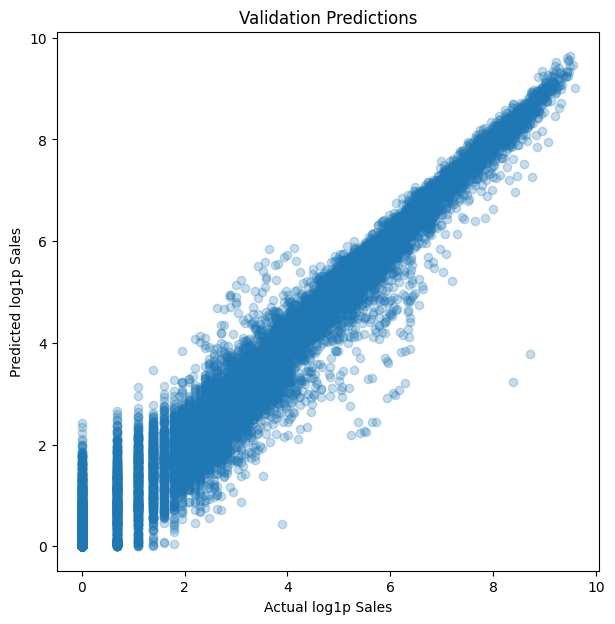

In [ ]:
plt.figure(figsize=(7, 7))
sample_diag = diagnostic.sample(
    min(15000, len(diagnostic)),
    random_state=42
)

plt.scatter(
    sample_diag["actual_log"],
    sample_diag["predicted_log"],
    alpha=0.25
)

plt.xlabel("Actual log1p Sales")
plt.ylabel("Predicted log1p Sales")
plt.title("Validation Predictions")
plt.show()

In [ ]:
final_lgb = LGBMRegressor(
    objective="regression_l1",
    n_estimators=1200,
    learning_rate=0.035,
    num_leaves=64,
    max_depth=-1,
    min_child_samples=40,
    subsample=0.90,
    colsample_bytree=0.90,
    reg_alpha=0.05,
    reg_lambda=0.10,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

final_lgb.fit(
    train_model[features],
    np.log1p(train_model["sales"])
)

test_lgb = np.expm1(
    final_lgb.predict(test_model[features])
)

test_lgb = np.clip(test_lgb, 0, None)

In [ ]:
final_cat = CatBoostRegressor(
    iterations=cat_model.get_best_iteration()
    if cat_model.get_best_iteration() > 0
    else 900,
    depth=8,
    learning_rate=0.04,
    loss_function="RMSE",
    l2_leaf_reg=6,
    random_seed=77,
    verbose=False
)

final_cat.fit(
    train_model[features],
    np.log1p(train_model["sales"]),
    verbose=False
)

test_cat = np.expm1(
    final_cat.predict(test_model[features])
)

test_cat = np.clip(test_cat, 0, None)

In [ ]:
final_prediction = (
    w_lgb * test_lgb +
    w_cat * test_cat
)

final_prediction = np.clip(
    final_prediction,
    0,
    None
)

pd.Series(final_prediction).describe()

count    28512.000000
mean       422.325652
std       1144.997041
min          0.000000
25%          3.880222
50%         26.392135
75%        240.160128
max      14318.289768
dtype: float64

In [ ]:
sample = pd.read_csv(
    "/kaggle/input/competitions/store-sales-time-series-forecasting/sample_submission.csv"
)
submission = pd.DataFrame({
    "id": test_model["id"].values,
    "sales": final_prediction
})

submission = (
    sample[["id"]]
    .merge(
        submission,
        on="id",
        how="left"
    )
)

submission["sales"] = (
    submission["sales"]
    .fillna(0)
    .clip(lower=0)
)
assert submission.shape == sample.shape
assert submission["id"].equals(sample["id"])
assert submission["sales"].isnull().sum() == 0
assert (submission["sales"] >= 0).all()

print(submission.shape)
print(submission["sales"].describe())
print("Submission is ready")
submission.to_csv(
    "/kaggle/working/submission.csv",
    index=False
)

print("/kaggle/working/submission.csv")
model_scores = pd.DataFrame({
    "Model": [
        "LightGBM",
        "CatBoost",
        "Final Blend"
    ],
    "RMSLE": [
        lgb_score,
        cat_score,
        best_blend["RMSLE"]
    ]
})

model_scores
model_scores.to_csv(
    "/kaggle/working/model_validation_scores.csv",
    index=False
)

blend_table.to_csv(
    "/kaggle/working/blend_search.csv",
    index=False
)
[
    f for f in os.listdir("/kaggle/working")
    if f.endswith(".csv")
]

(28512, 2)
count    28512.000000
mean       422.325652
std       1144.997041
min          0.000000
25%          3.880222
50%         26.392135
75%        240.160128
max      14318.289768
Name: sales, dtype: float64
Submission is ready
/kaggle/working/submission.csv


['model_validation_scores.csv', 'submission.csv', 'blend_search.csv']